# BetterScheduler: measured laptop walkthrough

This notebook reads the real 180-parent CPU pilot. It shows predictions, causal
sender memory, a serialized header, queue decisions and independent annotation
coverage. It does **not** run a codec, establish natural cross-view identity, or
turn the exposed development comparison into a final test.

Run from the project Python environment at
`../SemanticSchedulerEnd2End/.venv/Scripts/python.exe`. Dependencies are the
existing project environment plus nbformat, nbclient, matplotlib and pandas.
Source modules live in BetterScheduler; the recorded run manifest identifies
the snapshot actually used for the pilot. Current replay code can differ.
Outputs: this executed notebook, sibling cell logs, and `walkthrough_figures/`.
No network access or new model inference is required.

In [1]:
print("Setup: environment, repository and measured source run", flush=True)
import sys, json, platform, subprocess, time
from pathlib import Path
import importlib.metadata as metadata
ROOT=Path('D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticCommunication\\SemanticSchedulerParameterAudit'); SOURCE=Path('D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticCommunication\\SemanticSchedulerParameterAudit\\BetterScheduler\\results\\local\\20261025T082051Z')
sys.path.insert(0,str(ROOT))
print("Actual interpreter:",sys.executable,"Python:",platform.python_version())
print("Repository:",ROOT,"Source run:",SOURCE)
for package in ("numpy","torch","transformers","scikit-learn","nbformat"):
    print(package,metadata.version(package))
print("Current revision:",subprocess.check_output(["git","rev-parse","HEAD"],cwd=ROOT,text=True).strip())
manifest=json.loads((SOURCE/"manifest.json").read_text())
print("Pilot revision:",manifest.get("git_commit"),"Pilot Python:",manifest.get("python"))
import torch
print("Current CUDA available:",torch.cuda.is_available(),"Notebook uses cached CPU evidence only")
FIGURES=ROOT/"BetterScheduler"/"notebooks"/"walkthrough_figures"
FIGURES.mkdir(parents=True,exist_ok=True)
print("Setup complete; figure destination:",FIGURES)

Setup: environment, repository and measured source run


Actual interpreter: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\.venv\Scripts\python.exe Python: 3.12.14
Repository: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerParameterAudit Source run: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerParameterAudit\BetterScheduler\results\local\20261025T082051Z
numpy 2.5.3
torch 2.14.0
transformers 4.57.6
scikit-learn 1.9.1
nbformat 5.11.1
Current revision: 8947b399c6d0c178fe4cf870aa8a4700a960cf35
Pilot revision: 8947b399c6d0c178fe4cf870aa8a4700a960cf35 Pilot Python: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\.venv\Scripts\python.exe


Current CUDA available: False Notebook uses cached CPU evidence only
Setup complete; figure destination: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerParameterAudit\BetterScheduler\notebooks\walkthrough_figures


## 1. Separate evidence from truth

The source image supplies frozen image features. Mission clauses supply text
features. The runtime extractor sees those predictions and past sender memory.
Published labels are used only by training/evaluation, never by extraction.
Missing labels are unknown, not negatives. These sources lack verified events
and capture times; no event-held-out or freshness claim follows.

In [2]:
print("Stage 1: audit annotations and cached prediction schema",flush=True)
import pandas as pd
records=json.loads((SOURCE/"data/records.json").read_text())
print("Parents:",len(records),"Groups:",len({r["group"] for r in records}))
print(pd.Series([r["source"] for r in records]).value_counts())
display(pd.DataFrame([r["labels"] for r in records]).apply(lambda x:x.value_counts(dropna=False)))
from BetterScheduler.extractor import VisualEvidence,SemanticParameterExtractor,SenderMemory
raw={}
for line in (SOURCE/"features/clip.jsonl").read_text().splitlines():
    row=json.loads(line);raw[row["image_id"]]=VisualEvidence.from_dict(row["evidence"])
print("Prediction record attributes:",list(next(iter(raw.values())).to_dict()))
print("Stage 1 complete")

Stage 1: audit annotations and cached prediction schema


Parents: 180 Groups: 156
ladi     100
medic     80
Name: count, dtype: int64


,building_damage,road_damage,affected_people,structural_flooding
0.0,62,76,76,81
1.0,38,24,4,19
NaN,80,80,100,80


Prediction record attributes: ['embedding', 'similarities', 'probabilities', 'scene_scores', 'detections', 'width', 'height', 'statuses', 'provenance']
Stage 1 complete


## 2. Query memory, extract, serialize, then commit

The first observation has cold-start novelty. The same evidence after a
successful transmission should have zero embedding distance. Semantic-delta
novelty can also use changes in predicted mission conditions; it is not proof
that two photographs show the same physical asset. Memory is transmitter-side.
The receiver receives numerical fields, not the sender's whole knowledge base.

In [3]:
print("Stage 2: frozen heads and causal duplicate example",flush=True)
from BetterScheduler.contracts import MISSIONS,MethodSpecification
from BetterScheduler.learning import ClaimHeads
from BetterScheduler.serialization import HeaderCodec
directory=SOURCE/"metrics/clip"
spec=MethodSpecification(**json.loads((directory/"building_damage_specification.json").read_text()))
heads=ClaimHeads.from_dict(json.loads((directory/"claim_heads.json").read_text()))
enriched=heads.apply(raw)
extractor=SemanticParameterExtractor(spec)
memory=SenderMemory("example-sender","building_damage",capacity=spec.kb_capacity)
evidence=enriched[records[0]["image_id"]]
codec=HeaderCodec(spec.feature_names,spec.sha256,spec.quantization_bits)
for sequence in range(2):
    bundle=extractor.extract_evidence(evidence,MISSIONS["building_damage"],
        {"source_id":"example-sender","sequence":sequence,"image_token":str(sequence)},memory)
    header=codec.encode(bundle)
    print("Observation",sequence,"KB version before commit:",memory.version)
    print("Novelty:",bundle.parameters["novelty"].value)
    print("Header bytes:",len(header),"decoded fields:",codec.decode(header)["values"])
    memory.commit(evidence,sequence)
print("Selected fields:",spec.feature_names)
print("Stage 2 loaded saved producer/head/spec artifacts; no fitting")

Stage 2: frozen heads and causal duplicate example


Observation

 0 KB version before commit: 0
Novelty: {'distance': 1.0, 'cold_start': 1.0}
Header bytes: 56 decoded fields: {'novelty.cold_start': 1.0, 'novelty.distance': 1.0}
Observation 1 KB version before commit: 1
Novelty: {'distance': 0.0, 'cold_start': 0.0, 'added_building_damage': 0.0}
Header bytes: 56 decoded fields: {'novelty.added_building_damage': 0.0, 'novelty.cold_start': 0.0, 'novelty.distance': 0.0}
Selected fields: ('novelty.added_building_damage', 'novelty.cold_start', 'novelty.distance')
Stage 2 loaded saved producer/head/spec artifacts; no fitting


## 3. Queue evaluation and why early evidence matters

For each successful decode opportunity, distinct annotated fact coverage is
`C_k = exposed fact weight / offered fact weight`. `A10` averages `C_1` through
`C_10`, so earlier useful evidence receives more credit. An exact repeat adds no
new atom. Native image atoms measure distinct annotated observations, not
distinct real-world buildings. The cached pilot assumes successful service;
codec reconstruction and decoder failure experiments are separate work.

In [4]:
print("Stage 3: independent numerical metric reference",flush=True)
from INFRA.decoder_semantic_benchmark import coverage_metrics
facts={"A":{"building-1"},"B":{"building-1"},"C":{"building-2"}}
weights={"building-1":1.,"building-2":1.}
for order in (["A","B","C"],["A","C","B"]):
    result=coverage_metrics(order,facts,weights,k=3)
    print(order,result)
print("Hand calculation: repeat-first coverage .5,.5,1 => mean 2/3; diverse-first .5,1,1 => mean 5/6")
print("Stage 3 complete")

Stage 3: independent numerical metric reference


['A', 'B', 'C'] {'A_K': 0.6666666666666666, 'coverage_at_k': 1.0, 'curve': [0.5, 0.5, 1.0], 'marginal_gains': [0.5, 0.0, 0.5], 'critical_recall': None, 'weighted_redundancy': 0.3333333333333333, 'avoidable_zero_gain': 1, 'failures': 0, 'unsupported_claims': 0, 'offered_fact_count': 2, 'offered_weight': 2.0, 'covered_facts': ['building-1', 'building-2']}
['A', 'C', 'B'] {'A_K': 0.8333333333333334, 'coverage_at_k': 1.0, 'curve': [0.5, 1.0, 1.0], 'marginal_gains': [0.5, 0.5, 0.0], 'critical_recall': None, 'weighted_redundancy': 0.3333333333333333, 'avoidable_zero_gain': 0, 'failures': 0, 'unsupported_claims': 0, 'offered_fact_count': 2, 'offered_weight': 2.0, 'covered_facts': ['building-1', 'building-2']}
Hand calculation: repeat-first coverage .5,.5,1 => mean 2/3; diverse-first .5,1,1 => mean 5/6
Stage 3 complete


## 4. Actual provisional results

These are development-selected values on a single grouped split. They are
optimistic selection results, not locked test effects. Only four MEDIC parents
carry positive affected-people labels, so that stress result is especially weak.
Spatial evidence, useful task complexity, geography and trusted temporal
metadata are not validated by their absence in this pilot.

Stage 4: measured comparisons and costs


,backbone,mission,A10,groups,header_bytes
0,clip,building_damage,0.412228,['novelty'],56
1,clip,road_damage,0.418889,"['relevance', 'novelty', 'scene']",67
2,clip,affected_people,0.983333,"['novelty', 'scene']",66
3,siglip,building_damage,0.420012,"['relevance', 'novelty']",57
4,siglip,road_damage,0.323056,"['relevance', 'novelty', 'scene']",67
5,siglip,affected_people,0.983333,"['relevance', 'novelty', 'scene']",67


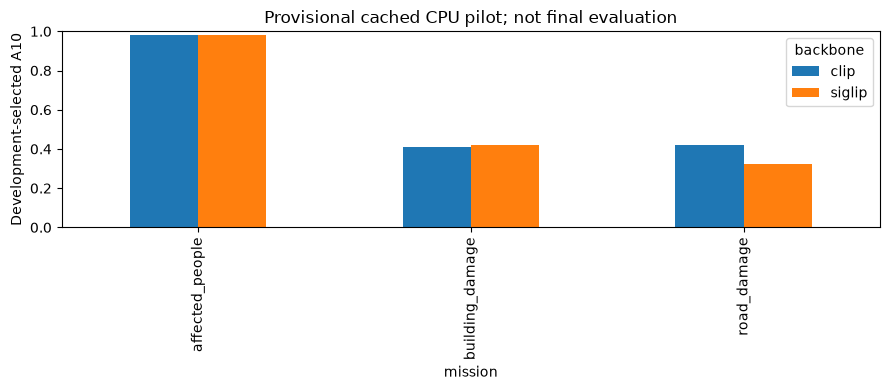

# BetterScheduler laptop pilot

Scope: real local CPU extraction and exposed-development parameter comparison. No final generalization or superiority claim.
Parents: 180. Event identities are not verified. Native observation atoms and exact-copy controls are separate.
No neural codec inference or VLM labels are used. No automatic distress/urgency labels are created.

## clip
Measured extraction wall time: 68.897 s; forward-only: 31.003 s.
- building_damage: provisional groups ['novelty'], methods similarity__semantic_delta, development A10=0.4122; header=56 bytes.
- road_damage: provisional groups ['relevance', 'novelty', 'scene'], methods similarity__embedding, development A10=0.4189; header=67 bytes.
- affected_people: provisional groups ['novelty', 'scene'], methods claim_probability__embedding, development A10=0.9833; header=66 bytes.
## siglip
Measured extraction wall time: 126.814 s; forward-only: 111.843 s.
- building_damage: provisional groups ['relevance', 'novelty'], methods 

In [5]:
print("Stage 4: measured comparisons and costs",flush=True)
import matplotlib.pyplot as plt
rows=[]
for backbone in ("clip","siglip"):
    results=json.loads((SOURCE/"metrics"/backbone/"summary.json").read_text())
    for mission,result in results.items():
        chosen=result.get("selected")
        if chosen:
            rows.append({"backbone":backbone,"mission":mission,"A10":chosen["mean_A10"],
                         "groups":str(chosen["groups"]),"header_bytes":chosen["header_bytes"]})
table=pd.DataFrame(rows);display(table)
fig,ax=plt.subplots(figsize=(9,4))
table.pivot(index="mission",columns="backbone",values="A10").plot.bar(ax=ax)
ax.set_ylim(0,1);ax.set_ylabel("Development-selected A10");ax.set_title("Provisional cached CPU pilot; not final evaluation")
fig.tight_layout();fig.savefig(FIGURES/"development_A10.png",dpi=160);plt.show()
print((SOURCE/"PILOT_REPORT.md").read_text())
print("Stage 4 complete; figure saved")

## 5. What remains before freezing a deployable specification

Run the corrected serialized-header replay, verify saved-head single/batch CLI
behaviour, then nested grouped selection on fresh supported data. Compare strong
baselines with explicit information profiles. Any unavailable parameter remains
unresolved. Two-GPU ownership and numerical parity must pass before a cloud
extraction campaign. A final test is opened only after selection is frozen.

In [6]:
print("Walkthrough complete. This notebook inspected cached evidence only.")
print("Measured source:",SOURCE)
print("Figures:",FIGURES)
print("See BetterScheduler/PLAN.md and KAGGLE_RUNS.md for current execution state.")

Walkthrough complete. This notebook inspected cached evidence only.
Measured source: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerParameterAudit\BetterScheduler\results\local\20261025T082051Z
Figures: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerParameterAudit\BetterScheduler\notebooks\walkthrough_figures
See BetterScheduler/PLAN.md and KAGGLE_RUNS.md for current execution state.
